# Algoritmo K-means (agrupamiento)

K-Means es un algoritmo **no supervisado de Clustering**. Se utiliza cuando tenemos un montón de datos sin etiquetar. El objetivo de este algoritmo es el de encontrar “K” grupos (clusters) entre los datos crudos, basado en sus características, iterando una cantidad `n` de veces.

Como resultado de ejecutar el algoritmo tendremos:

*   Los “centroids” de cada grupo que serán unas “coordenadas” de cada uno de los K conjuntos que se utilizarán para poder etiquetar nuevas muestras.
*   Etiquetas para el conjunto de datos de entrenamiento. Cada etiqueta perteneciente a uno de los K grupos formados.

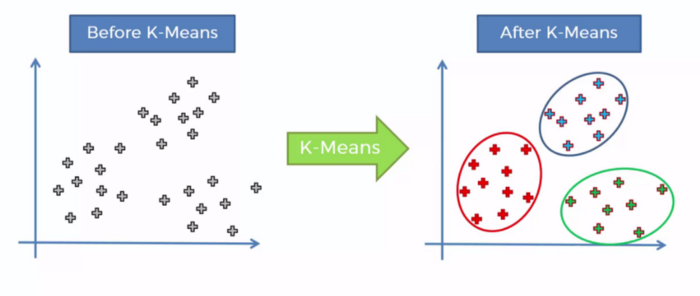

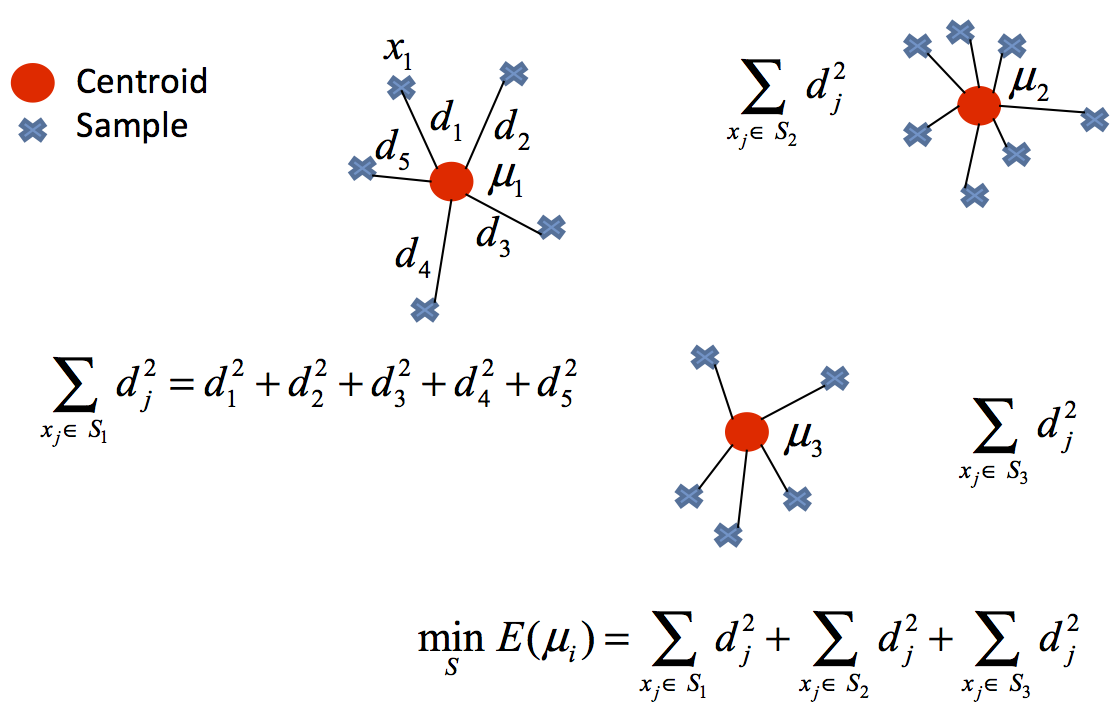

In [9]:
from sklearn.cluster import KMeans  # Técnica de agrupamiento.
from sklearn import datasets        # sklearn tiene datasets que podemos utilizar.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from mpl_toolkits.mplot3d import Axes3D
plt.rcParams['figure.figsize'] = (16, 9)
plt.style.use('ggplot')

# Dataset Iris

Este conjunto de datos consta de 3 tipos diferentes de longitud de pétalos y sépalos de iris (Setosa, Versicolor y Virginica), almacenados en un `numpy.ndarray` de 150x4.

Las filas son las muestras y las columnas son: longitud del sépalo, ancho del sépalo, longitud del pétalo y ancho del pétalo.

Consulte [aquí](https://en.wikipedia.org/wiki/Iris_flower_data_set) para obtener más información sobre este conjunto de datos.

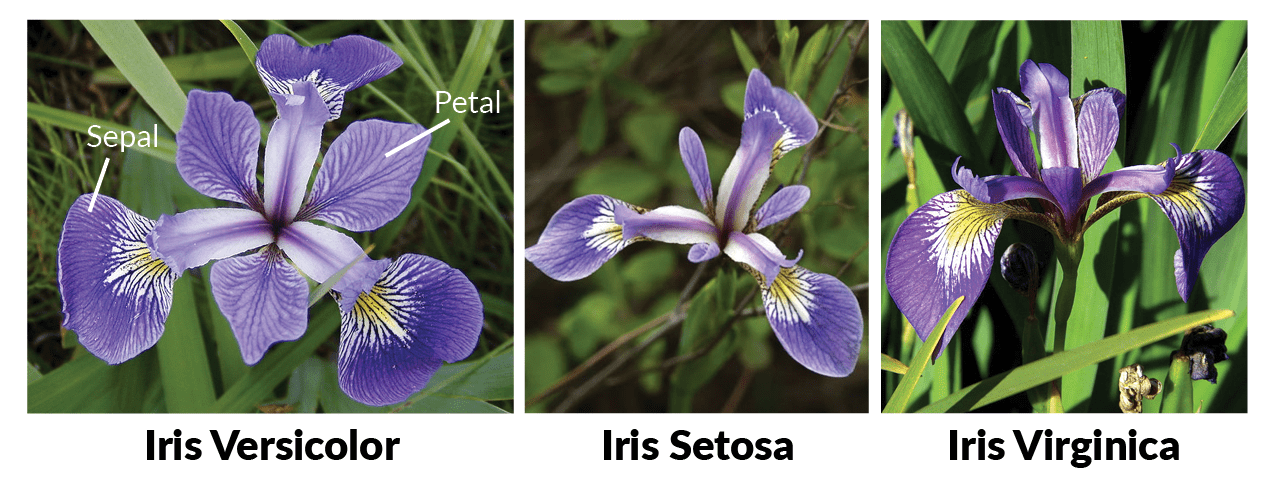

## Cargando el data set de Iris

In [10]:
# Cargamos el data set de Iris
iris= datasets.load_iris()
iris

{'data': array([[5.1, 3.5, 1.4, 0.2],
        [4.9, 3. , 1.4, 0.2],
        [4.7, 3.2, 1.3, 0.2],
        [4.6, 3.1, 1.5, 0.2],
        [5. , 3.6, 1.4, 0.2],
        [5.4, 3.9, 1.7, 0.4],
        [4.6, 3.4, 1.4, 0.3],
        [5. , 3.4, 1.5, 0.2],
        [4.4, 2.9, 1.4, 0.2],
        [4.9, 3.1, 1.5, 0.1],
        [5.4, 3.7, 1.5, 0.2],
        [4.8, 3.4, 1.6, 0.2],
        [4.8, 3. , 1.4, 0.1],
        [4.3, 3. , 1.1, 0.1],
        [5.8, 4. , 1.2, 0.2],
        [5.7, 4.4, 1.5, 0.4],
        [5.4, 3.9, 1.3, 0.4],
        [5.1, 3.5, 1.4, 0.3],
        [5.7, 3.8, 1.7, 0.3],
        [5.1, 3.8, 1.5, 0.3],
        [5.4, 3.4, 1.7, 0.2],
        [5.1, 3.7, 1.5, 0.4],
        [4.6, 3.6, 1. , 0.2],
        [5.1, 3.3, 1.7, 0.5],
        [4.8, 3.4, 1.9, 0.2],
        [5. , 3. , 1.6, 0.2],
        [5. , 3.4, 1.6, 0.4],
        [5.2, 3.5, 1.5, 0.2],
        [5.2, 3.4, 1.4, 0.2],
        [4.7, 3.2, 1.6, 0.2],
        [4.8, 3.1, 1.6, 0.2],
        [5.4, 3.4, 1.5, 0.4],
        [5.2, 4.1, 1.5, 0.1],
  

In [11]:
# Dividimos el DF. En 'x' tenemos los datos para el aprendizaje. En 'y' tenemos
  # la información objetivo.
x = pd.DataFrame(iris.data, columns=iris.feature_names)
y = pd.DataFrame(iris.target, columns=['Target'])

In [12]:
x.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [13]:
y.head()

,Target
0,0
1,0
2,0
3,0
4,0


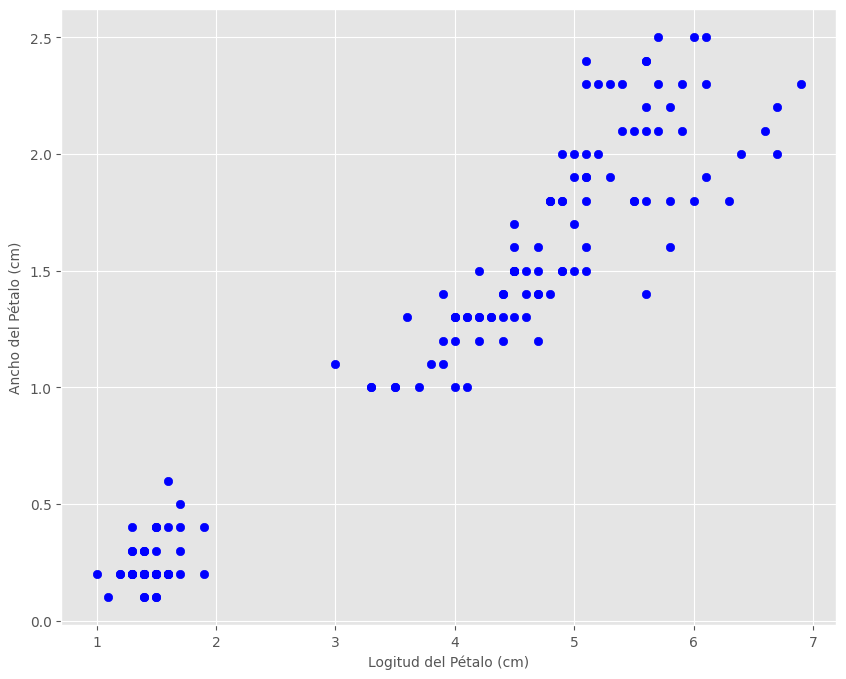

In [14]:
# Graficamos la relación entre la longitud del pétalo y el ancho del pétalo.
fig, ax = plt.subplots(figsize=(10, 8))
plt.scatter(x['petal length (cm)'], x['petal width (cm)'], c='blue')
plt.xlabel('Logitud del Pétalo (cm)', fontsize=10)
plt.ylabel('Ancho del Pétalo (cm)', fontsize=10)
plt.show()

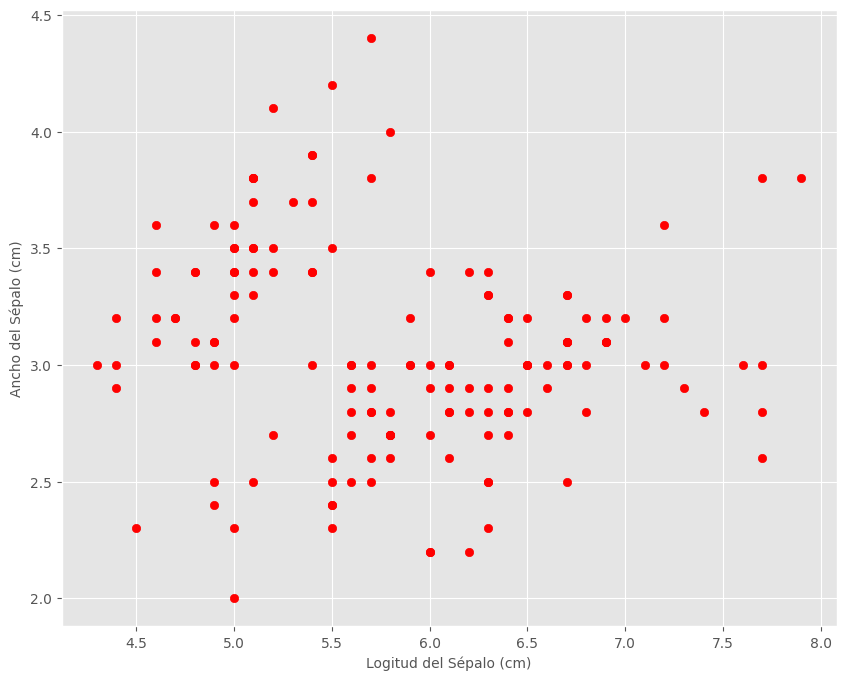

In [15]:
# Graficamos la relación entre la longitud del sépalo y el ancho del sépalo.
fig, ax = plt.subplots(figsize=(10, 8))
plt.scatter(x['sepal length (cm)'], x['sepal width (cm)'], c='red')
plt.xlabel('Logitud del Sépalo (cm)', fontsize=10)
plt.ylabel('Ancho del Sépalo (cm)', fontsize=10)
plt.show()

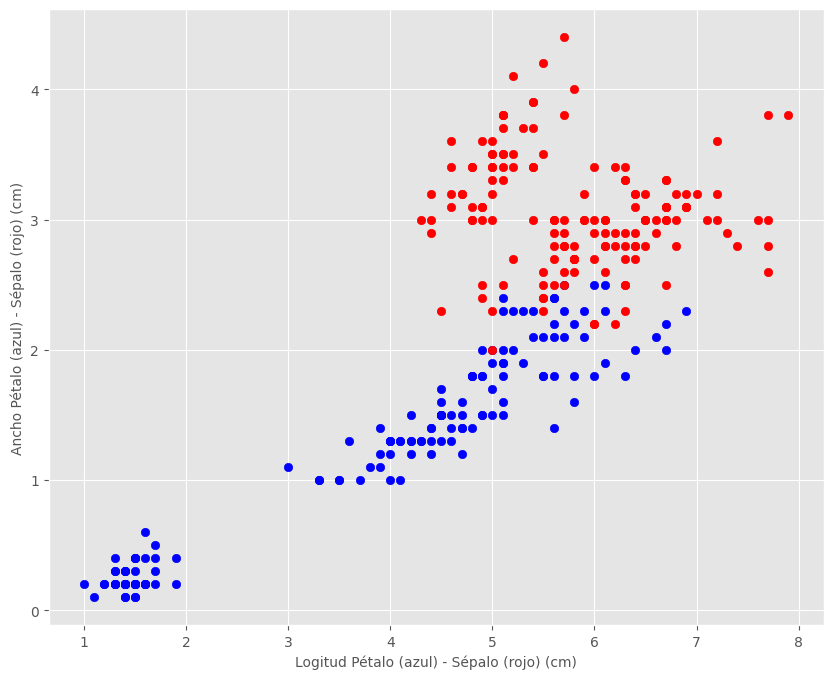

In [16]:
# Grafiquemos las relaciones de ambas longitudes.
fig, ax = plt.subplots(figsize=(10, 8))
plt.scatter(x['petal length (cm)'], x['petal width (cm)'], c='blue')
plt.scatter(x['sepal length (cm)'], x['sepal width (cm)'], c='red')
plt.xlabel('Logitud Pétalo (azul) - Sépalo (rojo) (cm)', fontsize=10)
plt.ylabel('Ancho Pétalo (azul) - Sépalo (rojo) (cm)', fontsize=10)
plt.show()

## Construcción y evaluación del modelo con K-Means

In [18]:
# Creamos el modelo con los respectivos parámetros.
model = KMeans(n_clusters=3, max_iter=1000, random_state=0)
# Entrenamos el modelo con los datos de 'x'.
model.fit(x)
# En ésta variable guardamos todas aquellas etiquetas que encontró el modelo
  # basado en la similitud de los datos.
y_labels = model.labels_

In [20]:
# Guardamos en 'y_kmeans' los valores de la predicción del modelo.
y_kmeans = model.fit_predict(x)

print('Predicciones: ', y_kmeans)

Predicciones:  [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 0 2 2 2 2 2 0 2 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


In [21]:
from sklearn import metrics
# Calculamos la exactitud del modelo con los datos de entrada 'Y_iris' que
  # obtuvimos al cargar el DS. Y 'y_kmeans' que son los datos de predicción.
accuracy = metrics.adjusted_rand_score(iris.target, y_kmeans)
print(accuracy)

0.7163421126838476


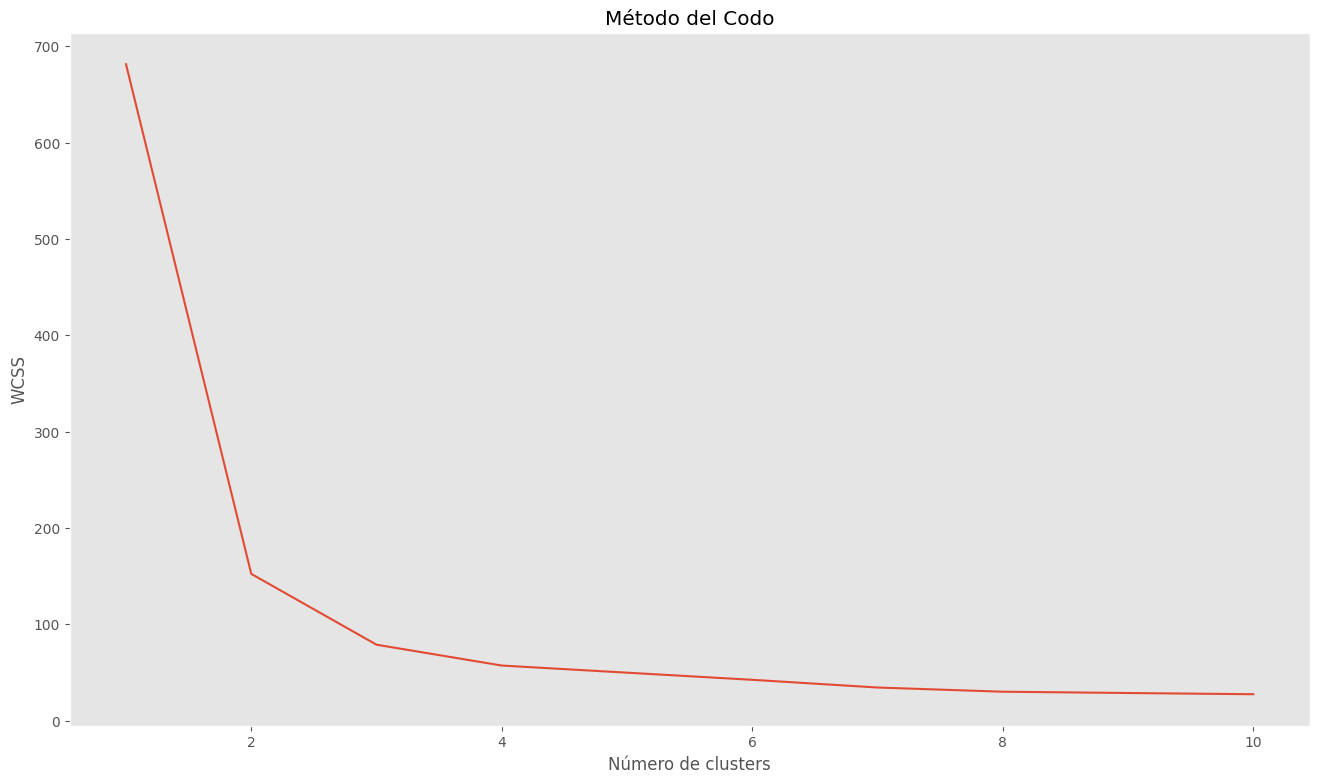

In [22]:
# Código para hacer el cálculo del numero de cluster usando el Método del Codo.
# WCSS: Within-Cluster-Sum-of-Squares (Suma de los Cuadrados de las Distancias
  # dentro del cluster).

wcss = []

for i in range(1, 11):
  kmeans = KMeans(n_clusters=i, max_iter=1000, random_state=0)
  kmeans.fit(x)
  wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss)
plt.title('Método del Codo')
plt.xlabel('Número de clusters')
plt.ylabel('WCSS')
plt.grid()
plt.show()

De la gráfica anterior, obtenida por la técnica del codo, podemos observar que fue correcta la selección del número del clusters cuando creamos el modelo con `KMeans`: 3 clusters es el número ideal.

**¿Cuál sería el el valor de exactitud si escogemos 2 clusters?**

In [29]:
# Creamos el modelo con los respectivos parámetros
model_2 = KMeans(n_clusters=2, max_iter=1000, random_state=0)

# Entrenamos el modelo con los datos de x
model_2.fit(x)

# Guardamos las etiquetas encontradas por el modelo
y_labels_2  = model_2.labels_

# Guardamos las predicciones del modelo
y_kmeans_2c = model_2.predict(x)

# Calculamos la exactitud comparando las etiquetas reales (iris.target) con las predichas usando el índice Rand ajustado
accuracy_2c = adjusted_rand_score(iris.target, y_kmeans_2c)

# Mostramos la exactitud
print(accuracy_2c)

0.5399218294207123


In [30]:
# Creamos un nuevo modelo con 4 clusters
model_3 = KMeans(n_clusters=5, max_iter=1000, random_state=0)

# Entrenamos el modelo con los datos de x
model_3.fit(x)

# Guardamos las etiquetas encontradas por el modelo
y_labels_3 = model_3.labels_

# Guardamos las predicciones del modelo
y_kmeans_4c = model_3.predict(x)

# Calculamos el índice Rand ajustado
accuracy_4c = adjusted_rand_score(iris.target, y_kmeans_4c)

# Mostramos el resultado
print(accuracy_4c)

0.6498176853819967


**Trabajo en clase: ¿Cuál sería el valor de exactitud si escogemos 4 clusters?**

In [33]:
# Creamos un nuevo modelo con 3 clusters
model_4 = KMeans(n_clusters=4, max_iter=1000, random_state=0)

# Entrenamos el modelo con los datos de x
model_4.fit(x)

# Guardamos las etiquetas encontradas por el modelo
y_labels_4 = model_4.labels_

# Guardamos las predicciones del modelo
y_kmeans_3c = model_4.predict(x)

# Calculamos el índice Rand ajustado
accuracy_3c = adjusted_rand_score(iris.target, y_kmeans_3c)

# Mostramos el resultado
print(accuracy_3c)

0.692705847366269


## Graficando el modelo

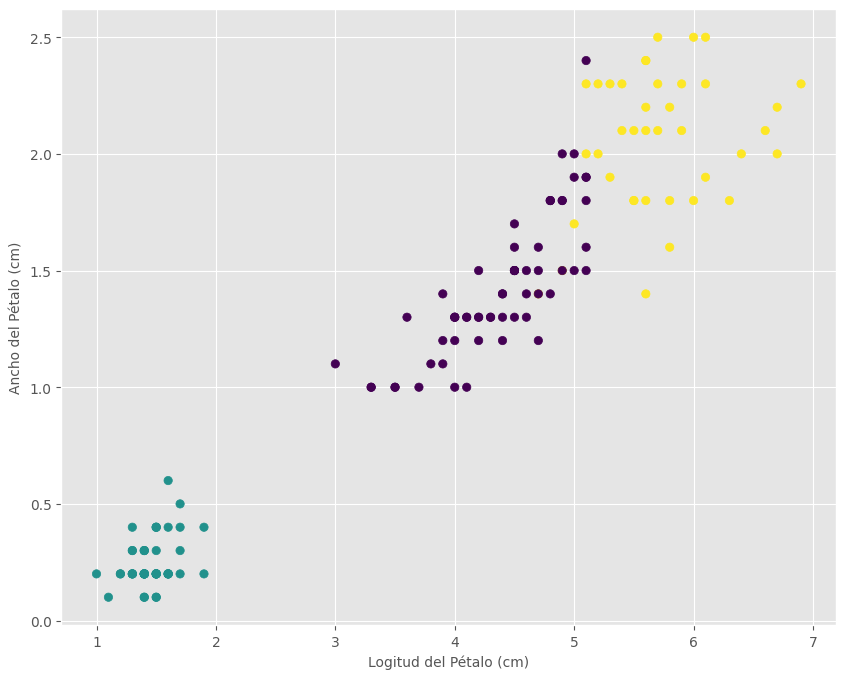

In [34]:
# 'c' es color y varía dependiendo de los valores de 'y_kmeans'.
# 's' es el tamaño de cada punto.
fig, ax = plt.subplots(figsize=(10, 8))
plt.scatter(x['petal length (cm)'], x['petal width (cm)'], c=y_kmeans)
plt.xlabel('Logitud del Pétalo (cm)', fontsize=10)
plt.ylabel('Ancho del Pétalo (cm)', fontsize=10)
plt.show()

# Dataset 140 usuarios en Twitter

El dataset `140people.csv` contiene 140 celebridades del mundo en diferentes areas: deporte, cantantes, actores, etc. Basado en una metodología de psicología conocida como “Ocean: The Big Five” tendemos como características de entrada:

*   `usuario`: el nombre en Twitter.
*   `op`: Openness to experience – grado de apertura mental a nuevas experiencias, curiosidad, arte.
*   `co`: Conscientiousness – grado de orden, prolijidad, organización.
*   `ex`: Extraversion – grado de timidez, solitario o participación ante el grupo social.
*   `ag`: Agreeableness – grado de empatía con los demás, temperamento.
*   `ne`: Neuroticism, – grado de neuroticismo, nervioso, irritabilidad, seguridad en sí mismo.
*   `Wordcount`: Cantidad promedio de palabras usadas en sus tweets.
*   `Categoria`: Actividad laboral del usuario (actor, cantante, etc.).

El dataset contiene 9 categorías diferenes -actividades laborales- que son:

1.   Actor/actriz
2.   Cantante
3.   Modelo
4.   Tv, series
5.   Radio
6.   Tecnología
7.   Deportes
8.   Política
9.   Escritor

El objetivo es utilizar el algoritmo **K-means** para que agrupe estos usuarios -no por su actividad laboral- si no, por sus similitudes en la personalidad.

Para casos reales, podemos utilizar todas las dimensiones que necesitemos; sin embargo, sólo utilizaremos 3 en este ejemplo, de modo que podamos graficar los grupos resultantes.

Una de las hipótesis que podríamos tener es: *Todos los cantantes tendrán personalidad parecida* (y así con cada rubro laboral). Con esta técnica podemos observar si los grupos están, o no están relacionados necesariamente con la actividad de estas Celebridades.



In [41]:
# Librerías de cálculo y manipulación de datos.
import pandas as pd
import numpy as np
# Librarías para graficar.
import matplotlib.pyplot as plt
import seaborn as sns
# Librería para realizar agrupamiento.
from sklearn.cluster import KMeans
from google.colab import files


In [40]:
uploaded = files.upload()

Saving 140people.csv to 140people (1).csv


In [39]:
df_140people = pd.read_csv('140people.csv')
df_140people.head()

,usuario,op,co,ex,ag,ne,wordcount,categoria
0,3gerardpique,34.297953,28.148819,41.948819,29.370315,9.841575,37.0945,7
1,aguerosergiokun,44.986842,20.525865,37.938947,24.279098,10.362406,78.7970,7
2,albertochicote,41.733854,13.745417,38.999896,34.645521,8.836979,49.2604,4
3,AlejandroSanz,40.377154,15.377462,52.337538,31.082154,5.032231,80.4538,2
4,alfredocasero1,36.664677,19.642258,48.530806,31.138871,7.305968,47.0645,4


## Datos estadísticos de las variables numéricas

In [42]:
# Descripción estadística.
df_140people.describe()

,op,co,ex,ag,ne,wordcount,categoria
count,140.000000,140.000000,140.000000,140.000000,140.000000,140.000000,140.000000
mean,44.414591,22.977135,40.764428,22.918528,8.000098,98.715484,4.050000
std,8.425723,5.816851,7.185246,7.657122,3.039248,44.714071,2.658839
min,30.020465,7.852756,18.693542,9.305985,1.030213,5.020800,1.000000
25%,38.206484,19.740299,36.095722,17.050993,6.086144,66.218475,2.000000
50%,44.507091,22.466718,41.457492,21.384554,7.839722,94.711400,3.500000
75%,49.365923,26.091606,45.197769,28.678866,9.758189,119.707925,7.000000
max,71.696129,49.637863,59.824844,40.583162,23.978462,217.183200,9.000000


In [43]:
# Para conocer la cantidad de celebridades por categoría:
print(df_140people.groupby('categoria').size())

categoria
1    27
2    34
3     9
4    19
5     4
6     8
7    17
8    16
9     6
dtype: int64


Como vemos tenemos 34 cantantes, 27 actores, 17 deportistas, 16 políticos, etc.

In [44]:
# Informe general del DataSet por columnas.
df_140people.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 140 entries, 0 to 139
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   usuario    140 non-null    object 
 1   op         140 non-null    float64
 2   co         140 non-null    float64
 3   ex         140 non-null    float64
 4   ag         140 non-null    float64
 5   ne         140 non-null    float64
 6   wordcount  140 non-null    float64
 7   categoria  140 non-null    int64  
dtypes: float64(6), int64(1), object(1)
memory usage: 8.9+ KB


## Matriz de correlación de variables numéricas

In [45]:
# Creación de nuevo DataSet de Pandas únicamente con las variables numéricas.
varNum = df_140people.drop(['usuario'], axis=1)

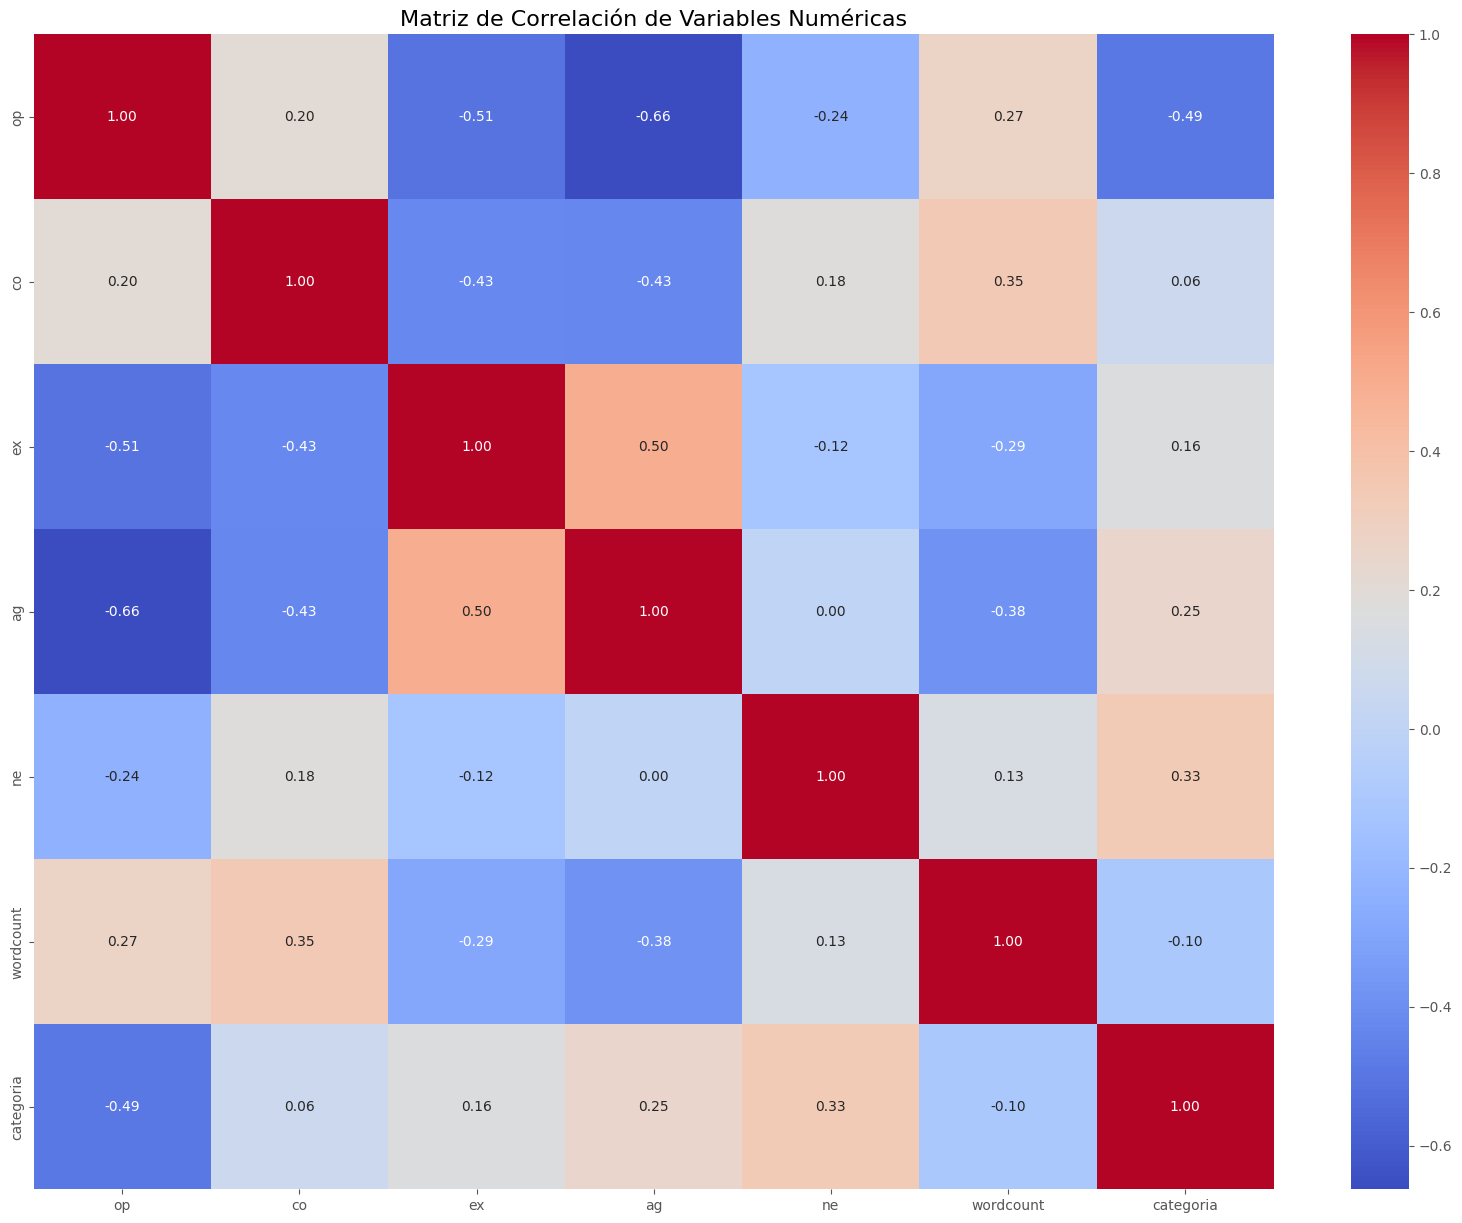

In [46]:
fig, ax = plt.subplots(figsize=(20, 15))
sns.heatmap(varNum.corr(), annot=True, cmap='coolwarm', fmt='.2f', ax=ax)
plt.title('Matriz de Correlación de Variables Numéricas', fontsize=16)
plt.show()

## Visualización de Datos

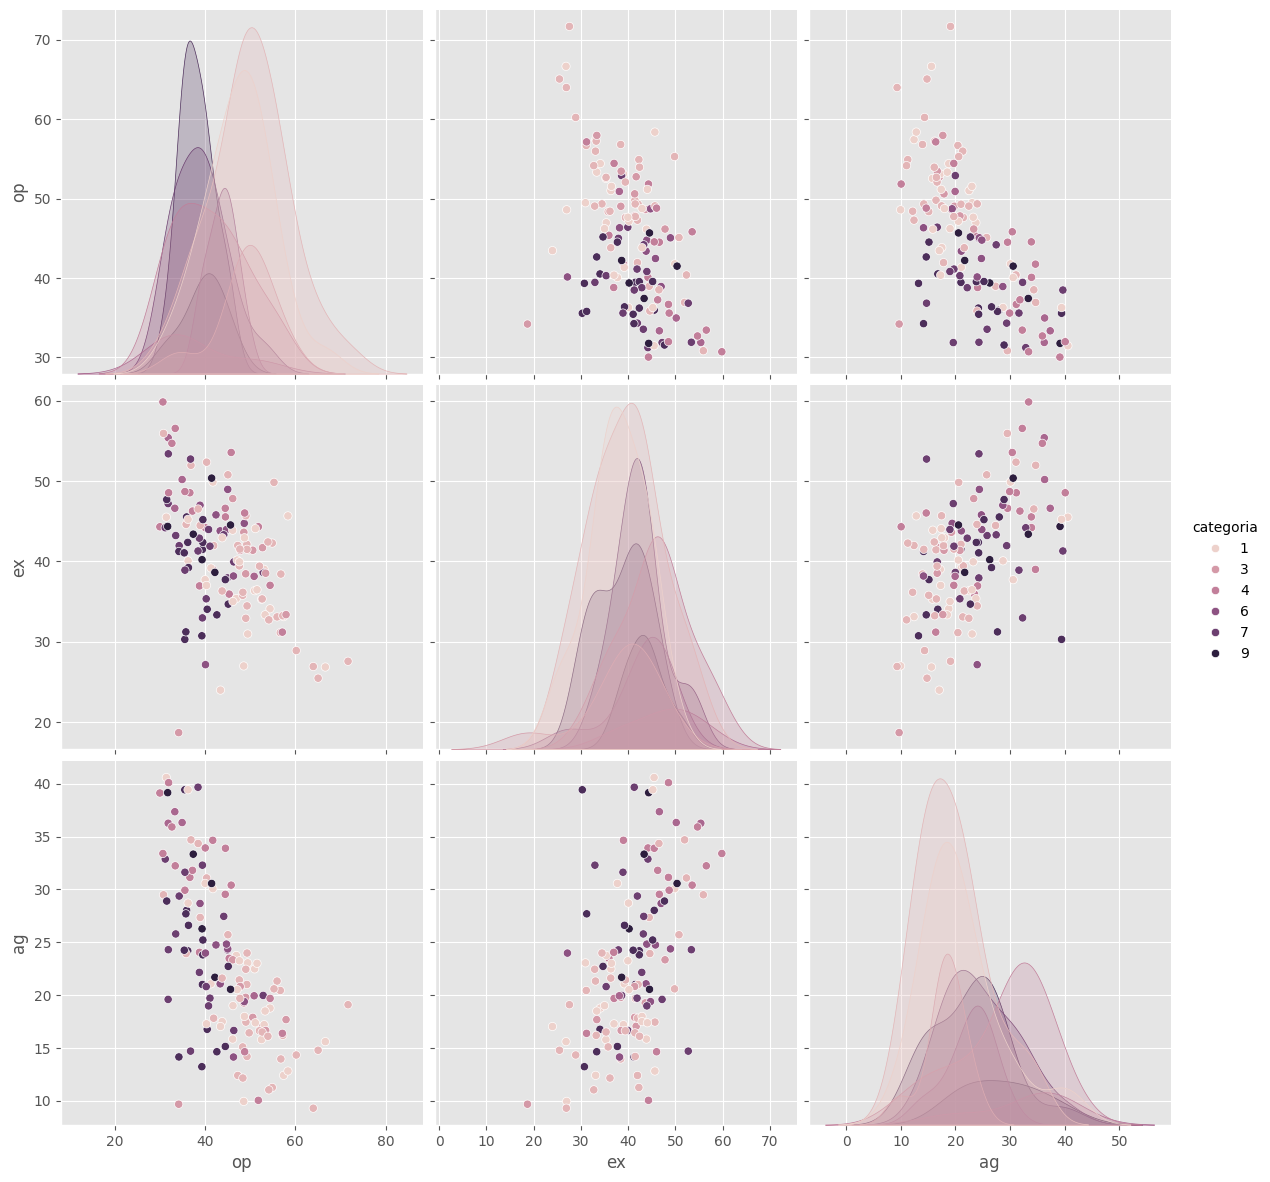

In [47]:
sns.pairplot(data=df_140people.dropna(),
             hue='categoria',
             height=4,
             vars=["op","ex","ag"],
             kind='scatter');

## Algoritmo K-means

### Definimos la entrada de datos

In [54]:
X = np.array(df_140people[["op","ex","ag"]])
y = np.array(df_140people['categoria'])
X.shape

(140, 3)

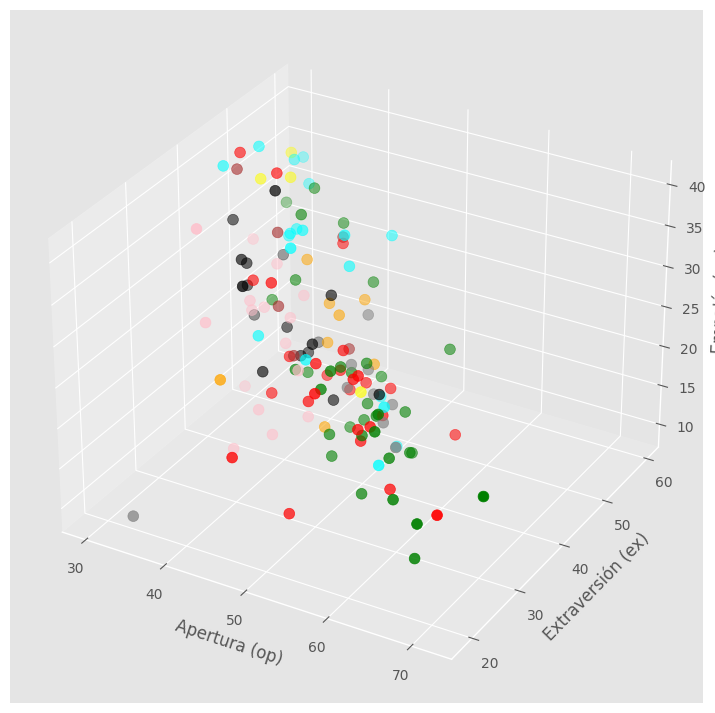

In [60]:
# Ahora veremos una gráfica en 3D con 9 colores representando las categorías utilizando la sintaxis moderna.
fig = plt.figure(figsize=(16, 9))
ax = fig.add_subplot(projection='3d')

colores=['blue','red','green','grey','cyan','yellow','orange','black','pink','brown','purple']
asignar=[]
for row in y:
    asignar.append(colores[row])

# Creamos el gráfico de dispersión en 3D
ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=asignar, s=60)

# Etiquetas de los ejes para mejor comprensión
ax.set_xlabel('Apertura (op)')
ax.set_ylabel('Extraversión (ex)')
ax.set_zlabel('Empatía (ag)')

plt.show()

### Obtener el valor K

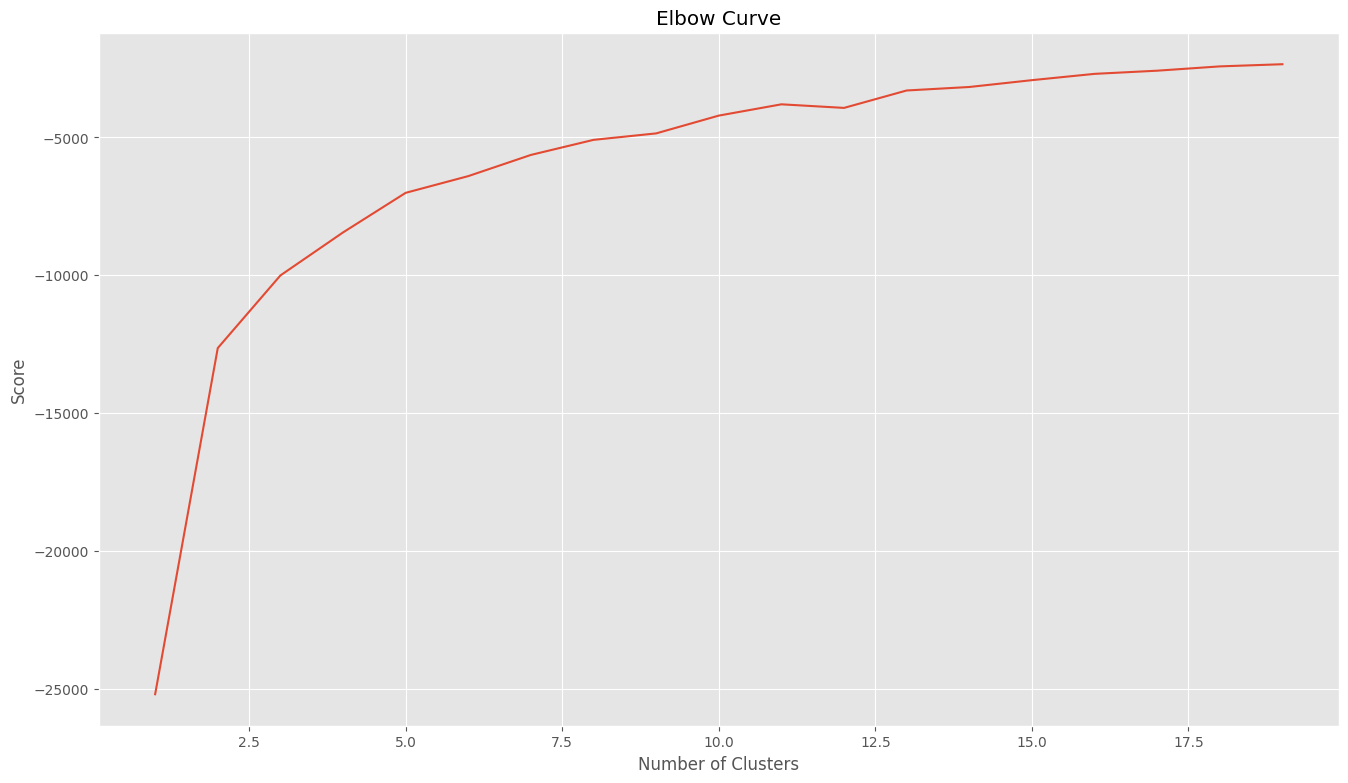

In [61]:
Nc = range(1, 20)

kmeans = [KMeans(n_clusters=i) for i in Nc]
score = [kmeans[i].fit(X).score(X) for i in range(len(kmeans))]

plt.plot(Nc,score)
plt.xlabel('Number of Clusters')
plt.ylabel('Score')
plt.title('Elbow Curve')
plt.show()

Como la curva es bastante “suave”, se puede considerar a 5 como un buen número para K.

### Ejecutamos K-Means

Ejecutamos el algoritmo para 5 clusters y obtenemos las etiquetas y los centroides.

In [62]:
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances_argmin_min

In [63]:
import numpy as np

# Definimos X con las variables del dataset
X = np.array(df_140people[["op","ex","ag"]])

kmeans = KMeans(n_clusters=5).fit(X)
centroids = kmeans.cluster_centers_
print(centroids)

[[42.35918174 33.17901191 21.9112827 ]
 [39.71802394 44.17116283 25.21565671]
 [50.15530371 40.81295548 17.39048745]
 [34.6623442  49.02931536 34.23419588]
 [58.70462307 30.53566167 15.72207033]]


Se pueden observar los 5 conjuntos de centroides y en cada uno, el punto para las features `["op","ex","ag"]`.

Ahora veremos esto en una gráfica 3D con colores para los grupos y veremos si se diferencian: (las estrellas marcan el centro de cada cluster).

In [51]:
# Predicción de clusters por medio de la función 'predict()'.
labels = kmeans.predict(X)
labels

array([3, 1, 3, 3, 3, 0, 0, 3, 4, 1, 4, 0, 2, 4, 0, 4, 3, 0, 4, 3, 3, 4,
       1, 3, 4, 1, 0, 0, 0, 4, 0, 4, 4, 4, 3, 3, 3, 3, 0, 1, 0, 0, 0, 0,
       2, 2, 4, 4, 3, 0, 4, 0, 0, 2, 3, 2, 1, 4, 1, 2, 1, 1, 4, 2, 0, 0,
       2, 2, 2, 3, 0, 1, 4, 4, 1, 2, 0, 3, 3, 3, 3, 0, 2, 4, 1, 0, 4, 0,
       4, 4, 4, 1, 1, 4, 4, 0, 3, 4, 3, 4, 2, 4, 4, 3, 2, 4, 0, 0, 0, 4,
       4, 3, 3, 3, 0, 4, 1, 2, 3, 0, 1, 3, 4, 1, 2, 1, 1, 4, 4, 1, 4, 4,
       1, 0, 2, 3, 3, 2, 4, 3], dtype=int32)

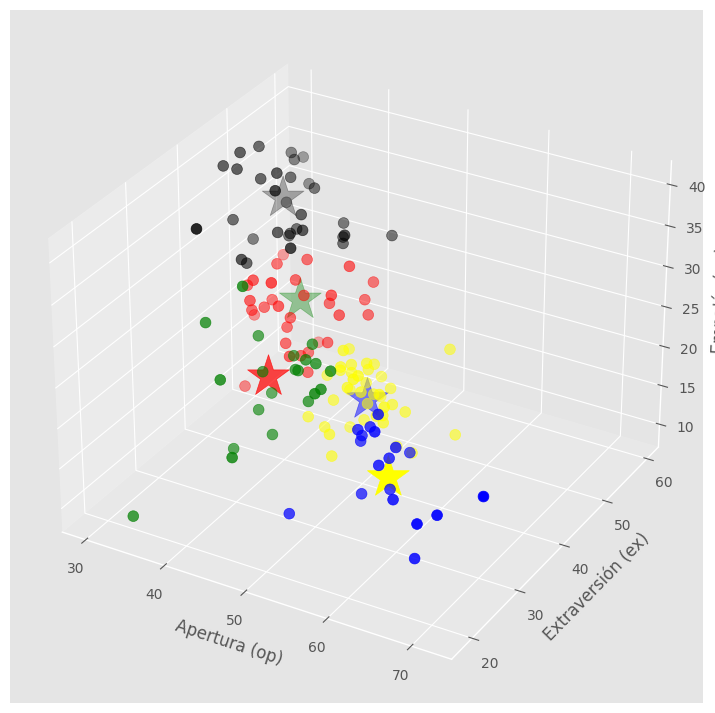

In [76]:
# Obteniendo los centroides.
C = kmeans.cluster_centers_
colores=['red','green','blue','black','yellow']
asignar=[]
for row in labels:
    asignar.append(colores[row])

# Inicializamos la figura con la proyección 3D moderna
fig = plt.figure(figsize=(16, 9))
ax = fig.add_subplot(projection='3d')

# Graficamos los datos de los usuarios en 3D
ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=asignar, s=60)

# Graficamos los 5 centroides (estrellas grandes)
ax.scatter(C[:, 0], C[:, 1], C[:, 2], marker='*', c=colores, s=1000)

# Etiquetas explicativas de cada eje
ax.set_xlabel('Apertura (op)')
ax.set_ylabel('Extraversión (ex)')
ax.set_zlabel('Empatía (ag)')

plt.show()

Aqui podemos ver que el algoritmo de K-Means con `K = 5` ha agrupado a los 140 usuarios Twitter por su personalidad, teniendo en cuenta las 3 dimensiones que utilizamos: **Openess**, **Extraversion** y **Agreeablenes**. Pareciera que no hay necesariamente una relación en los grupos con sus actividades siendo famosos.

Haremos 3 gráficas en 2 dimensiones con las proyecciones a partir de nuestra gráfica 3D para que nos ayude a visualizar los grupos y su clasificación:

### Relación `op` - `ex`

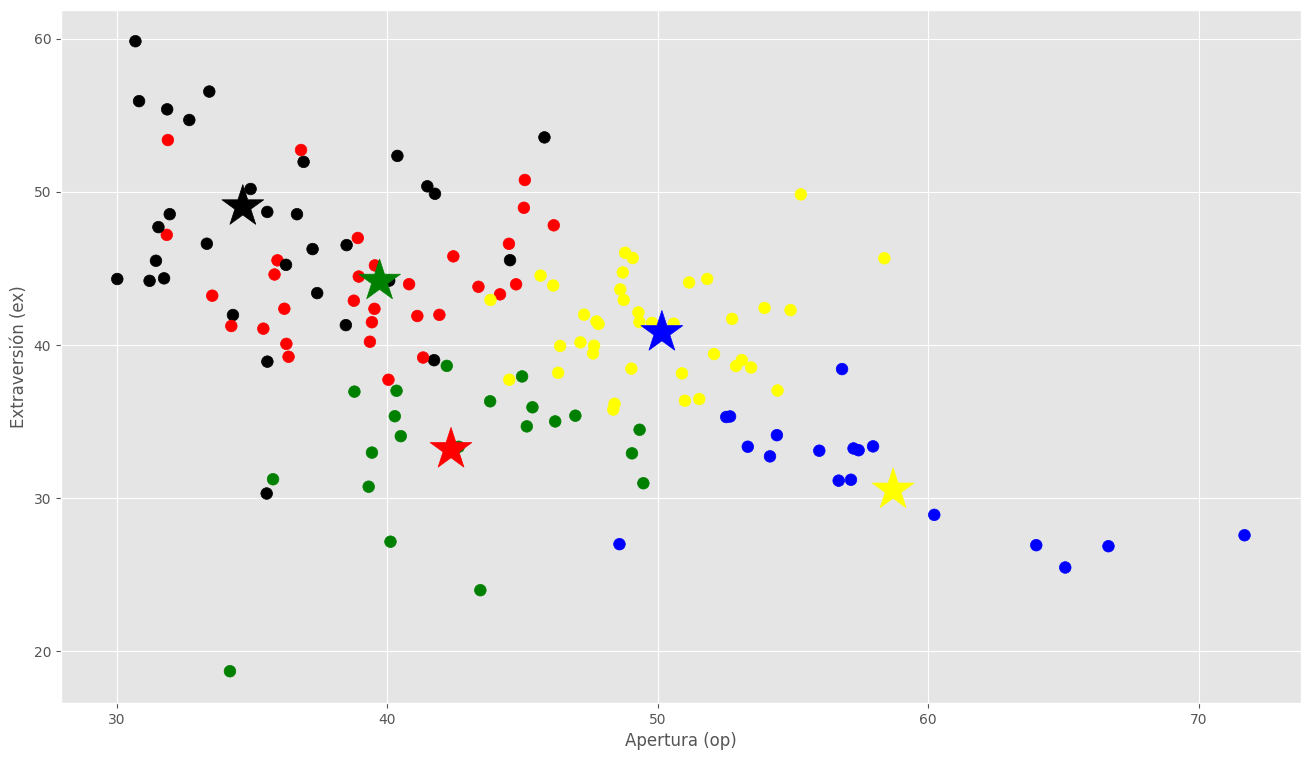

In [73]:
f1 = df_140people['op'].values
f2 = df_140people['ex'].values

# Gráfica en 2D comparando Apertura (op) y Extraversión (ex)
plt.scatter(f1, f2, c=asignar, s=70)
plt.scatter(C[:, 0], C[:, 1], marker='*', c=colores, s=1000)
plt.xlabel('Apertura (op)')
plt.ylabel('Extraversión (ex)')
plt.show()

### Relación `op` - `ag`

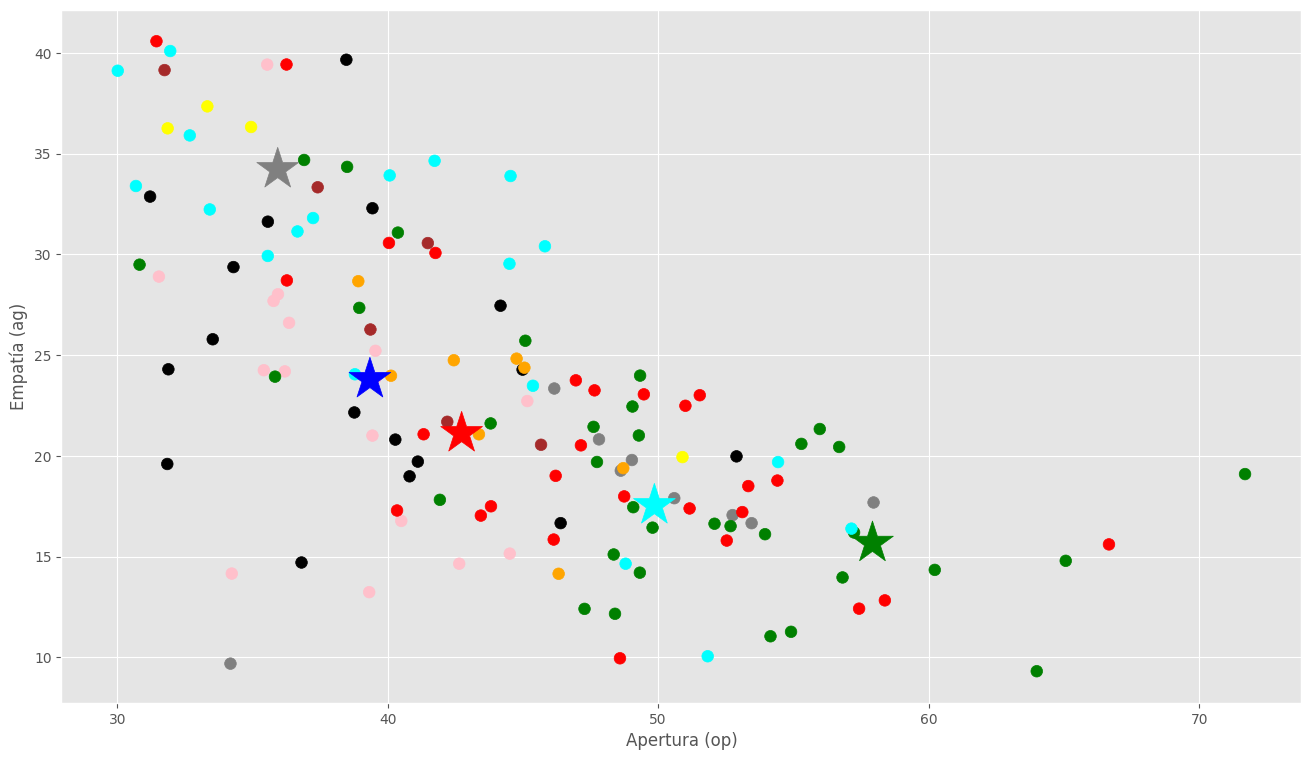

In [65]:
f1 = df_140people['op'].values
f2 = df_140people['ag'].values

# Graficamos los datos de los usuarios con sus respectivas etiquetas de cluster asignadas
plt.scatter(f1, f2, c=asignar, s=70)

# Graficamos los 5 centroides limitando la lista de colores a los primeros 5 elementos
plt.scatter(C[:, 0], C[:, 2], marker='*', c=colores[:5], s=1000)
plt.xlabel('Apertura (op)')
plt.ylabel('Empatía (ag)')
plt.show()

### Relación `ex` - `ag`

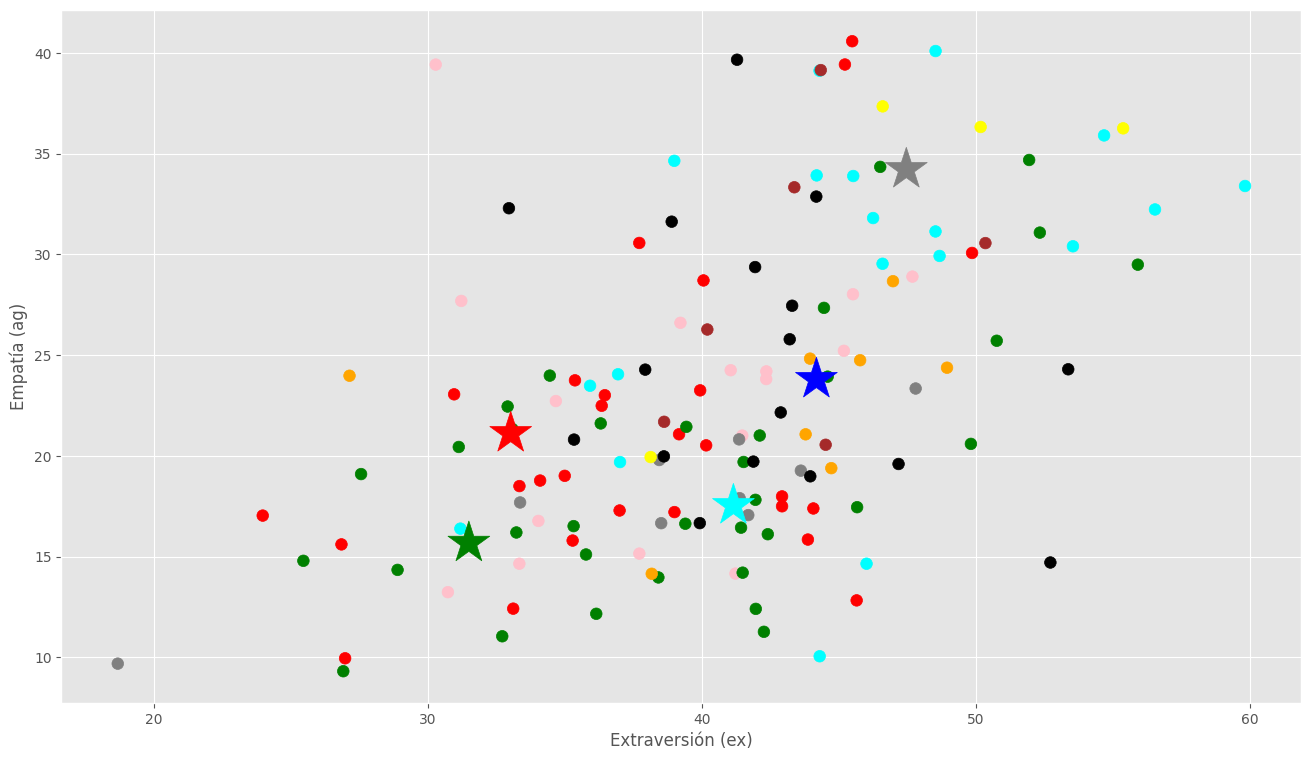

In [69]:
f1 = df_140people['ex'].values
f2 = df_140people['ag'].values

# Graficamos la distribución de usuarios (Extraversión vs Empatía)
plt.scatter(f1, f2, c=asignar, s=70)

# Graficamos los 5 centroides limitando la paleta de colores a los primeros 5 elementos
plt.scatter(C[:, 1], C[:, 2], marker='*', c=colores[:5], s=1000)
plt.xlabel('Extraversión (ex)')
plt.ylabel('Empatía (ag)')
plt.show()

En estas gráficas vemos que están bastante bien diferenciados los grupos.

Podemos ver cada uno de los clusters cuántos usuarios tiene:

In [70]:
copy =  pd.DataFrame()
copy['usuario'] = df_140people['usuario'].values
copy['categoria'] = df_140people['categoria'].values
copy['label'] = labels;
cantidadGrupo =  pd.DataFrame()
cantidadGrupo['color'] = colores
cantidadGrupo['cantidad'] = copy.groupby('label').size()
cantidadGrupo

,color,cantidad
0,blue,31.0
1,red,21.0
2,green,18.0
3,grey,31.0
4,cyan,39.0
5,yellow,NaN
6,orange,NaN
7,black,NaN
8,pink,NaN
9,brown,NaN


De esta forma podemos ver la diversidad en rubros laborales de cada uno. El número en frente a cada color es la cantidad de famosos con la misma actividad laboral.

También podemos saber cuántos usuarios de Twitter encajaron de cada categoría encajaran en el grupo 0 (rojo).

In [77]:
group_referrer_index = copy['label']==0
group_referrals = copy[group_referrer_index]

diversidadGrupo =  pd.DataFrame()
diversidadGrupo['categoria']=[0,1,2,3,4,5,6,7,8,9]
diversidadGrupo['cantidad']=group_referrals.groupby('categoria').size()
diversidadGrupo

,categoria,cantidad
0,0,NaN
1,1,3.0
2,2,4.0
3,3,1.0
4,4,1.0
5,5,NaN
6,6,5.0
7,7,8.0
8,8,8.0
9,9,1.0


Si en la tabla de arriba hay categorías vacías, quiere decir que de dicho grupo, no se encontraron predicciones.

¿Las categorías están bastante distribuídas sin que predomine una en particular?

Esta misma tabla se puede hacer para los clusters restantes: 1, 2, 3 y 4.

Podemos buscar los famosos que están más cerca a los centroides de cada grupo que podríamos decir que tienen los rasgos de personalidad característicos que representan a cada cluster:

In [79]:
# Vemos el representante del grupo, el usuario cercano a su centroide.
closest, _ = pairwise_distances_argmin_min(kmeans.cluster_centers_, X)
closest

array([ 91, 107,  21,  35,  82])

In [83]:
users = df_140people['usuario'].values
for row in closest:
    print(users[row])

kobebryant
Pablo_Iglesias_
carmenelectra
DaniMateoAgain
JudgeJudy


En los centros vemos que tenemos una política, una periodista, una jueza, una actriz y un político

### Clasificar nuevas muestras

Y finalmente podemos agrupar y etiquetar nuevos usuarios twitter con sus características y clasificarlos. Vemos el ejemplo con el usuario de David Guetta y nos devuelve que pertenece al grupo 4 (amarillo).

In [81]:
X_new = np.array([[45.92,57.74,15.66]]) #davidguetta

new_labels = kmeans.predict(X_new)
print(new_labels)

[2]


# Referencias

[1] [Understanding K-means Clustering in Machine Learning](https://towardsdatascience.com/understanding-k-means-clustering-in-machine-learning-6a6e67336aa1)

[2] [El algoritmo k-means aplicado a clasificación y procesamiento de imágenes](https://www.unioviedo.es/compnum/laboratorios_py/kmeans/kmeans.html)

[3] [How to program the kmeans algorithm in Python from scratch](https://anderfernandez.com/en/blog/kmeans-algorithm-python/)

[4] [K-Means Clustering in Python: A Practical Guide](https://realpython.com/k-means-clustering-python/)